# Visualizing fire scars

Author: Eden Gonzalez

Repository: https://github.com/edengonzalezz/eds220-hwk4.git

## About 

Create true and false color imagery to visualize the fire scars of the Eaton and Palisades fires in Los Angeles County in January 2025.

### Purpose

The purpose of this notebook is to create a false color image of the Eaton and Palisades Fires using remote sensing data to highlight the fire scars and explore how coding and data visualization support large-scale environmental monitoring. Overall, the workflow shows expected procedures (data expoloration, coordinate reference system wrangling, mapping) for remote sensing analysis in Python. 

### Highlights
* Use fundamental spatial processing packages
    - `geopandas`, `xarray`, `rioxarray`
* Geospatial workflows and CRS 
* Plot shapefiles and raster data
* Compare true color imagery with false color imagery 

### Datasets

* The satellite data used for this analysis comes from Microsoft's Landsat Collection 2 Level-2 Dataset. Data from this dataset is atmospherically corrected surface reflectance data that was collected by the Landsat 8 satllite. The Landsat image taken in January of 2025 contains 5 bands (red, green, blue, near-infrared, and shortwave infrared). The image was clipped to the greater Los Angeles County area which contains the fire perimeters. See more [here](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2).

* Data for the Eaton and Palisades Fire perimeters were provided by the Los Angeles County. Specifically, the fire perimeters were extracted from CAL FIRE's Historical Perimeter dataset. They note that the boundary polygons were dissolved for each fire to create a single fire burn perimeter. See more [here](https://egis-lacounty.hub.arcgis.com/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about).

### References

County of Los Angeles. (2025). Palisades and Eaton Dissolved Fire Perimeters (2025) [Data set]. https://egis-lacounty.hub.arcgis.com/maps/ad51845ea5fb4eb483bc2a7c38b2370c

Microsoft. (n.d.). Landsat Collection 2 Level-2. Microsoft Planetary Computer [Data set]. https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2



In [27]:
# Import packages
import os                           # Reading data
import numpy as np                  # Fast computing
import geopandas as gpd             # Geospatial data
import matplotlib.pyplot as plt     # Plotting 
import xarray as xr                 # Multi-dimensional arrays
import rioxarray as rioxr           # Raster processing

In [28]:
# Load Eaton fire perimeters 
fp = os.path.join('data','Eaton_Perimeter_20250121','Eaton_Perimeter_20250121.shp')
eaton = gpd.read_file(fp)
# Make sure it was loaded by seeing the first couple of rows
eaton.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},2025-01-08T00:00:00Z,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((-118.10093 34.16680, -118.1008..."


In [29]:
# Load Palisades fire perimeter
fp = os.path.join('data','Palisades_Perimieter_20250121','Palisades_Perimieter_20250121.shp')
palisades = gpd.read_file(fp)
# Make sure it was loaded by seeing the first couple of rows
palisades.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07T00:00:00Z,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((-118.51974 34.02996, -118.5198..."


## Fire perimeter data exploration

### Eaton

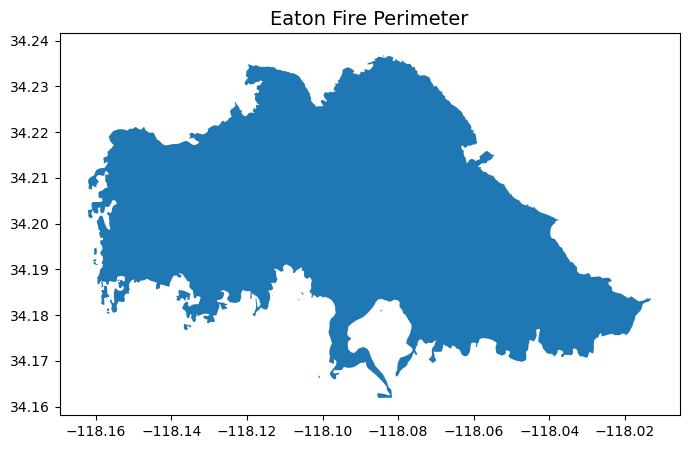

In [30]:
# It is good practice to plot geospatial data!
# This helps you see what you are working with

fig, ax = plt.subplots(figsize=(8,6))
eaton.plot(ax=ax)
ax.set_title("Eaton Fire Perimeter", fontsize=14)
plt.show()

In [31]:
# Observe fundamental data properties 
print(type(eaton))
print(type(eaton.geometry))
print(eaton.geom_type)
print(eaton.dtypes)

<class 'geopandas.geodataframe.GeoDataFrame'>
<class 'geopandas.geoseries.GeoSeries'>
0    MultiPolygon
dtype: object
OBJECTID         int64
YEAR_            int64
STATE           object
AGENCY          object
UNIT_ID         object
FIRE_NAME       object
type            object
INC_NUM         object
IRWINID         object
ALARM_DATE      object
CONT_DATE       object
CAUSE            int64
C_METHOD         int64
OBJECTIVE        int64
GIS_ACRES      float64
COMMENTS        object
COMPLEX_NA      object
COMPLEX_ID      object
FIRE_NUM        object
GlobalID        object
DECADES         object
Shape__Are     float64
Shape__Len     float64
geometry      geometry
dtype: object


In [32]:
# Explore the perimeter's CRS 
eaton.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [33]:
# CRS details
print('Ellipsoid: ', eaton.crs.ellipsoid)
print('Datum: ', eaton.crs.datum)
print('Is geographic?: ', eaton.crs.is_geographic)
print('Is projected?:', eaton.crs.is_projected )

Ellipsoid:  GRS 1980
Datum:  North American Datum 1983
Is geographic?:  True
Is projected?: False


### Palisades

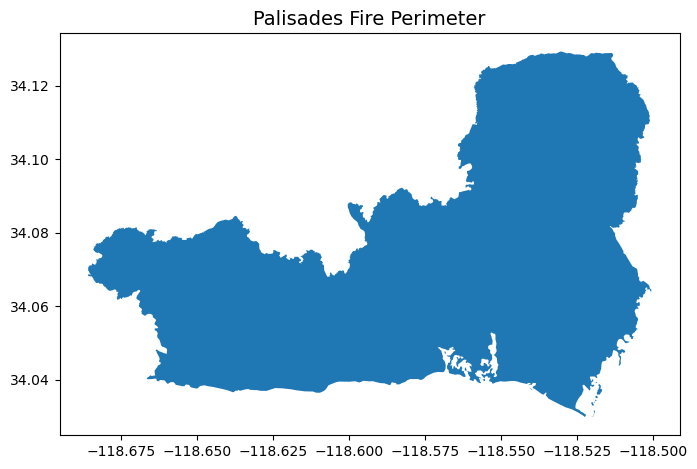

In [34]:
# Plot the palisades perimeter to help you see what you're working 
fig, ax = plt.subplots(figsize=(8,6))
palisades.plot(ax=ax)
ax.set_title("Palisades Fire Perimeter", fontsize=14)
plt.show()


In [35]:
# Observe fundamental data properties 
print(type(palisades))
print(type(palisades.geometry))
print(palisades.geom_type)
print(palisades.dtypes)

<class 'geopandas.geodataframe.GeoDataFrame'>
<class 'geopandas.geoseries.GeoSeries'>
0    MultiPolygon
dtype: object
OBJECTID         int64
YEAR_            int64
STATE           object
AGENCY          object
UNIT_ID         object
FIRE_NAME       object
type            object
INC_NUM         object
IRWINID         object
ALARM_DATE      object
CONT_DATE       object
CAUSE            int64
C_METHOD         int64
OBJECTIVE        int64
GIS_ACRES      float64
COMMENTS        object
COMPLEX_NA      object
COMPLEX_ID      object
FIRE_NUM        object
GlobalID        object
DECADES         object
Shape__Are     float64
Shape__Len     float64
geometry      geometry
dtype: object


In [36]:
# Explore the perimeter's CRS 
palisades.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [37]:
# CRS details
print('Ellipsoid: ', palisades.crs.ellipsoid)
print('Datum: ', palisades.crs.datum)
print('Is geographic?: ', palisades.crs.is_geographic)
print('Is projected?:', palisades.crs.is_projected )

Ellipsoid:  GRS 1980
Datum:  North American Datum 1983
Is geographic?:  True
Is projected?: False


The fire perimeter data for both the Eaton and Palisades fire were obtained from the [County of Los Angeles](https://egis-lacounty.hub.arcgis.com/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about). Since the data were from the same provider, there are many similarities. Both of the data are multipolygons that have a 2D geographic coordinate reference system opposed to projected. They use the GRS 1980 Ellipsoid and North American Datum 1963. In Python, both `eaton` and `palisades` are treated as `geopandas.geodataframe.GeoDataFrame`.

## NetCDF data import and exploration

In [38]:
# Import Landsat 8 data using xr.open_dataset()
fp = os.path.join('data', 'landsat8-2025-02-23-palisades-eaton.nc')
landsat = xr.open_dataset(fp)
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

In [39]:
# Explore landsat's fundamental data properties
print(landsat.dims)
print(landsat.coords)
print(landsat.dtypes)

FrozenMappingWarningOnValuesAccess({'y': 1418, 'x': 2742})
Coordinates:
  * y        (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x        (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time     datetime64[ns] 8B ...
Frozen({'red': dtype('float32'), 'green': dtype('float32'), 'blue': dtype('float32'), 'nir08': dtype('float32'), 'swir22': dtype('float32'), 'spatial_ref': dtype('int64')})


`landsat` is an `xarray.Dataset`. Its coordinates are x, y, and time with dimensions 'y': 1418, 'x': 2742. It has 6 variables: red, green, blue, nir08, swir22, and spatial_ref. Variables red, green, blue, nir08, and swir 22 are of data type float32 and have spatial_ref as thier grid mapping. 

## Restoring geospatial information

In [40]:
# Use rio.crs to print the CRS of this dataset
print('landsat CRS: ',landsat.rio.crs)

landsat CRS:  None


Currently, `landsat` is not a geospatial object as the command to print the CRS returned `None`.

In [41]:
# Print the CRS by accessing the spatial_ref.crs_wkt attribute of the dataset
# spatial_ref.crs_wkt contains all the geospatial information for the raster
print('landsat CRS: ',landsat.spatial_ref.crs_wkt)


landsat CRS:  PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


In [42]:
# Store landsat's spatial reference information into a variable
crs = landsat.spatial_ref.crs_wkt
print(crs)
# This is exactly the same as the CRS above

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


In [43]:
# Recover the geospatial information using rio.write_crs() 
landsat = landsat.rio.write_crs(crs)
# Print the CRS of the updated landsat data
print('landsat CRS: ',landsat.rio.crs)

landsat CRS:  EPSG:32611


Using the spatial_ref.crs_wkt attribute of the dataset, we were able to restore the geospatial information to the landsat raster. Now, the command to print the CRS returns a valid CRS, EPSG:36211.

## True color image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


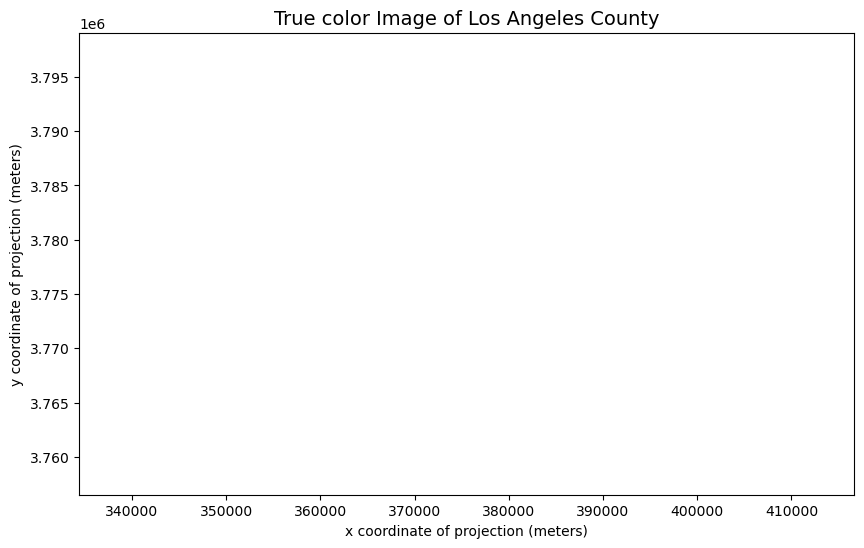

In [44]:
# First attempt at plotting true color image

# Initialize plot
fig, ax = plt.subplots(figsize=(10,6))

# Plot the red, green, and blue bands for true color imagery, order matters! 
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow()

# Label the x-axis 
ax.set_xlabel("x coordinate of projection (meters)")
# Label the y-axis
ax.set_ylabel("y coordinate of projection (meters)")

# Give plot a title
ax.set_title("True color Image of Los Angeles County", fontsize=14)

plt.show()

Plotting it such as how we did above gives a warning. This is because of the data types. The `landsat` bands are of data type `float64` which means that the values must be between 0.0 and 1.0. Matplotlib attempts to plot these values. However, since it does not match the expected inputs, the map is plotted incorrectly. 

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


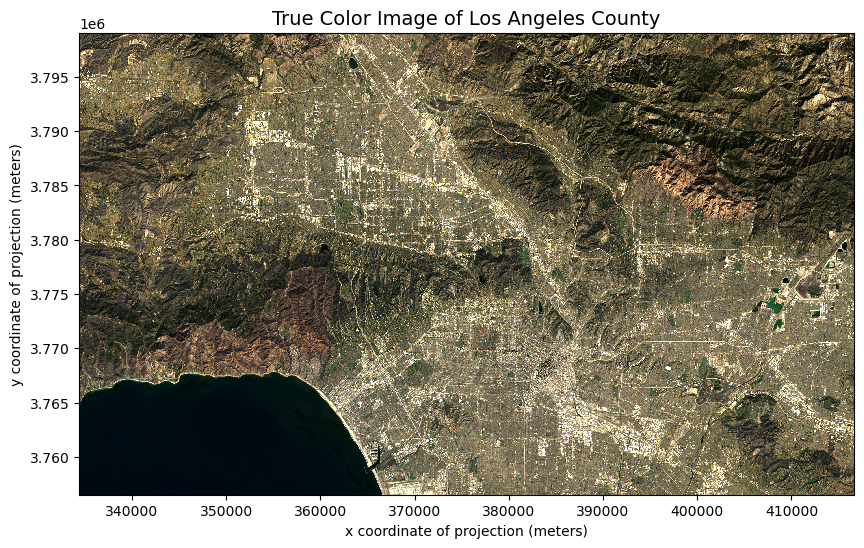

In [45]:
# Use the robust parameter to ignore extreme values (nans)

# Initialize plot
fig, ax = plt.subplots(figsize=(10,6))

# Set robust=True, this ignores those extreme values that are causing the incorrect plotting
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust=True, ax=ax)

# Set the x-axis label
ax.set_xlabel("x coordinate of projection (meters)")
# Set the y-axis label
ax.set_ylabel("y coordinate of projection (meters)")

ax.set_title("True Color Image of Los Angeles County", fontsize=14)

plt.show()

Now the data is plotted as expected. 

In [46]:
# Create a for loop to diagnose initial problem
# Identify the bands that have nans
bands = ['red', 'green', 'blue', 'nir08', 'swir22']
for band in bands:
    sum_na = int(np.isnan(landsat[band]).sum())
    print(f"The {band} band has {sum_na} missing values")

The red band has 0 missing values
The green band has 1 missing values
The blue band has 109 missing values
The nir08 band has 0 missing values
The swir22 band has 0 missing values


Text(0.5, 1.0, 'True Color Image of Los Angeles County')

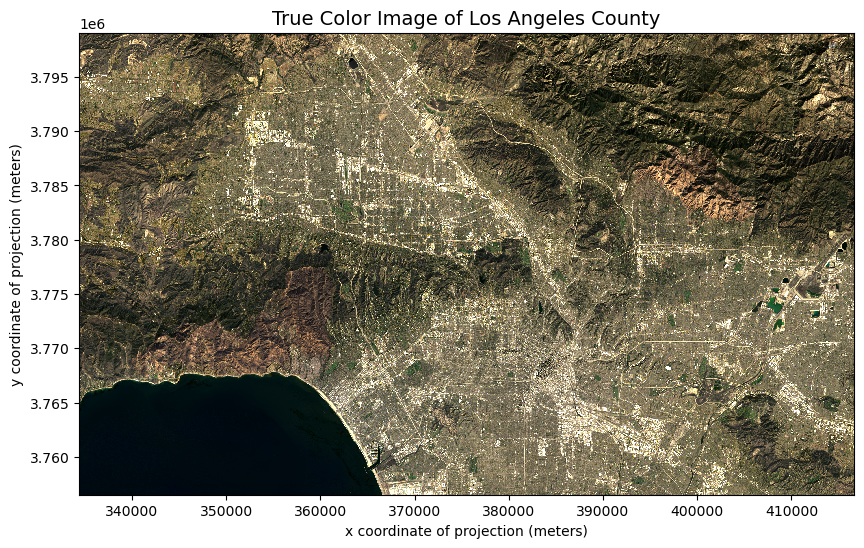

In [47]:
# Fill the missing values with 0s to take care of warnings

# Initialize plot
fig, ax = plt.subplots(figsize=(10,6))

# The missing values are filled using `.fillna(0)`
landsat[['red', 'green', 'blue']].to_dataarray().fillna(0).plot.imshow(robust=True)

# Set the x-axis label
ax.set_xlabel("x coordinate of projection (meters)")
# Set the y-axis label
ax.set_ylabel("y coordinate of projection (meters)")

ax.set_title("True Color Image of Los Angeles County", fontsize=14)

# Data is plotted as expected, with no warnings!

The invalid values (NAs) that the bands prevented `landsat` from being plotted as expected. The first plot had the correct axes, and even the same default axis labels, this suggests that the underlying issue in plotting was the values in the pixels. When the invalid values are filled with 0s, the bands are properly combined to produced the expected true color (RGB) image of Los Angeles County. 

In [48]:
## False color image

Text(0.5, 1.0, 'False Color Image of Los Angeles County')

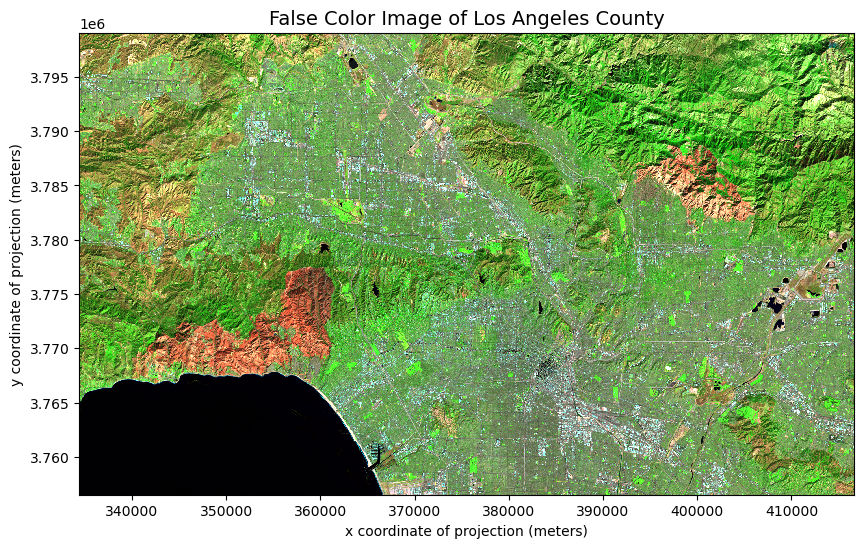

In [49]:
# Initialize plot
fig, ax = plt.subplots(figsize=(10,6))

# To create false color imagery:
# assign swir22 band to the red channel
# assign nir08 band to the green channel
# assign red band to the blue channel
# This is accomplished by subsetting landsat in that order
# Since these bands had no missing values (see above), .fillna() is not necessary

landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(robust=True)

# Set the x-axis label
ax.set_xlabel("x coordinate of projection (meters)")
# Set the y-axis label
ax.set_ylabel("y coordinate of projection (meters)")

ax.set_title("False Color Image of Los Angeles County", fontsize=14)


## Map

In [50]:
# Check the CRSs of all geospatial data
print('landsat CRS:',landsat.rio.crs)
print('eaton CRS:', eaton.crs)
print('palisades CRS:', palisades.crs)

landsat CRS: EPSG:32611
eaton CRS: EPSG:4269
palisades CRS: EPSG:4269


For plotting different geospatial data onto the same plot, the CRS must match! Since the CRS are different, we must reproject. Typically we reproject the smaller data to the bigger data. Landsat is the larger dataset, so reproject the fire perimeters and then make sure the CRSs all match.

In [51]:
# Reproject fire perimeters to landsat CRS
eaton = eaton.to_crs(landsat.rio.crs)
assert eaton.crs == landsat.rio.crs

# Verify that the CRSs match
palisades = palisades.to_crs(landsat.rio.crs)
assert palisades.crs == landsat.rio.crs

Since there is no error, that means that all CRSs match and we can begin plotting all three data.

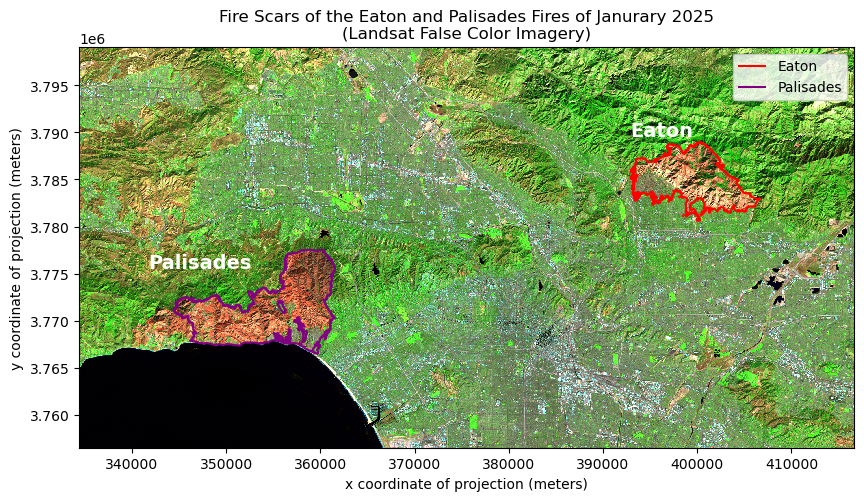

In [54]:
# Plot landsat false color image with the fire perimeters

# Initialize plot
fig, ax = plt.subplots(figsize = (10, 6))

# Plot the landsat false color image
landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(robust=True, ax=ax)

# Plot the Eaton fire perimeter
eaton.boundary.plot(ax=ax, color='red', label='Eaton')
# Plot the Palisades fire perimeter
palisades.boundary.plot(ax=ax, color='purple', label='Palisades')

ax.set_xlabel("x coordinate of projection (meters)")
ax.set_ylabel("y coordinate of projection (meters)")

# Hyperspecific text placement for eaton
eaton_x_min = eaton.get_coordinates().min().iloc[0]
eaton_y_max = eaton.get_coordinates().max().iloc[1]
# Hyperspecific text placement for palisades
palisades_x_middle = palisades.get_coordinates().median().iloc[0]
palisades_y_max = palisades.get_coordinates().max().iloc[1]
# Plot text
ax.text(eaton_x_min, eaton_y_max+500, "Eaton", fontsize=14, color = 'white', fontweight = 'bold', ha='left')
ax.text(palisades_x_middle, palisades_y_max -2000, "Palisades", color = 'white', fontsize=14, fontweight = 'bold', ha='right')

# Plot the legend
plt.legend()

# Add title
ax.set_title("Fire Scars of the Eaton and Palisades Fires of Janurary 2025\n(Landsat False Color Imagery)")

plt.show()


The map plots false color imagery of the Los Angeles County area overlayed with the Eaton Fire (red) and Palisades Fire (purple) perimeters. Specifically, the short wave infrared (swir22) band is assigned to the red channel, the near infrared (nir) band is assigned to the green channel, and red band is assigned to the blue channel. This combination and assignment of bands to channels is able to detect the fire burn scars, which are virtually invisble under true color (RGB) imagery. Although some mountainous terrain as a darker brown/orange color, the area within the fire perimeters are distinctly red, revealing the impact of the fires on the landscape.